<a href="https://colab.research.google.com/github/dhiru69-tech/ML-Techniques-Lab-Project/blob/main/notebooks/day11_knn_basics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 11: K-Nearest Neighbours (KNN)
**Course:** BO CDA 205, Machine Learning Techniques
**Dataset:** German Credit (1000 customers, 21 columns)
**Syllabus link:** Supervised learning, nearest neighbour classifiers

> **Goal of today:** Build KNN by hand, see why scaling matters, choose k with cross-validation, observe the curse of dimensionality, and pick the decision threshold using the training data only.

 ## 1. Setup

Same workflow as before: stratified split, preprocessing fitted on the training set only, and a pipeline for cross-validation.

`make_pipe(prep, **params)` builds a pipeline with the preprocessor we pass in and a KNN model with the given settings.

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.datasets import fetch_openml
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_score, cross_val_predict, GridSearchCV)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

# Load data. bad = 1 is the positive class
data = fetch_openml(name="credit-g", version=1, as_frame=True)
df = data.frame
X = df.drop(columns=['class'])
y = df['class'].map({'good': 0, 'bad': 1}).astype(int)

# Stratified 80/20 split with a fixed seed
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()

# Preprocessing 1: numeric columns scaled, categorical columns one-hot encoded
preprocess = ColumnTransformer(
    [('num', StandardScaler(), num_cols),
     ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)],
    sparse_threshold=0
)
preprocess.set_output(transform="pandas")

# Preprocessing 2 (for the scaling experiment): numeric columns left unscaled
prep_raw = ColumnTransformer(
    [('num', 'passthrough', num_cols),
     ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)],
    sparse_threshold=0
)
prep_raw.set_output(transform="pandas")


def make_pipe(prep=preprocess, **params):
    """Pipeline = preprocessing + KNN. params go to the KNN model."""
    return Pipeline([('prep', clone(prep)), ('knn', KNeighborsClassifier(**params))])


def evaluate(name, y_true, pred):
    """Main metrics for the positive class (bad = 1), plus the Day 8 cost."""
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {
        'model': name,
        'accuracy': round(accuracy_score(y_true, pred), 3),
        'precision': round(precision_score(y_true, pred, zero_division=0), 3),
        'recall': round(recall_score(y_true, pred, zero_division=0), 3),
        'f1': round(f1_score(y_true, pred, zero_division=0), 3),
        'FN': fn, 'FP': fp, 'cost': 5 * fn + fp,
    }


# 5-fold cross-validation that keeps the 70/30 ratio in every fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Processed (scaled + one-hot) arrays used for the by-hand parts
X_train_p = clone(preprocess).fit_transform(X_train)
X_test_p = clone(preprocess).fit(X_train).transform(X_test)
print("Train:", X_train_p.shape, "| Test:", X_test_p.shape)

Train: (800, 61) | Test: (200, 61)


## 2. Distance by Hand

For two rows **a** and **b**:

| Distance | Formula |
|---|---|
| Euclidean | square root of the sum of (a - b)² |
| Manhattan | sum of the absolute differences |

We compute both for two real customers, using only the **numeric** columns.

In [9]:
# Two customers from the training set (numeric columns only, as floats)
a = X_train[num_cols].iloc[0].astype(float)
b = X_train[num_cols].iloc[1].astype(float)
print(pd.DataFrame({'customer A': a, 'customer B': b}))

diff = a - b
euclid = np.sqrt((diff ** 2).sum())
manhattan = diff.abs().sum()
print("\nEuclidean distance:", round(euclid, 2))
print("Manhattan distance:", round(manhattan, 2))

# Which column contributes how much to the squared distance?
share = (diff ** 2) / (diff ** 2).sum()
print("\nShare of the squared distance, by column:")
print((share * 100).round(1).sort_values(ascending=False))

                        customer A  customer B
duration                      36.0        12.0
credit_amount               8335.0       804.0
installment_commitment         3.0         4.0
residence_since                4.0         4.0
age                           47.0        38.0
existing_credits               1.0         1.0
num_dependents                 1.0         1.0

Euclidean distance: 7531.04
Manhattan distance: 7565.0

Share of the squared distance, by column:
credit_amount             100.0
duration                    0.0
installment_commitment      0.0
residence_since             0.0
age                         0.0
existing_credits            0.0
num_dependents              0.0
dtype: float64


In [10]:
# The same two customers after scaling the numeric columns (fitted on train only)
scaler = StandardScaler().fit(X_train[num_cols])
a_s = pd.Series(scaler.transform(X_train[num_cols].iloc[[0]])[0], index=num_cols)
b_s = pd.Series(scaler.transform(X_train[num_cols].iloc[[1]])[0], index=num_cols)

diff_s = a_s - b_s
share_s = (diff_s ** 2) / (diff_s ** 2).sum()
print("Euclidean distance after scaling:", round(np.sqrt((diff_s ** 2).sum()), 2))
print("\nShare of the squared distance, by column:")
print((share_s * 100).round(1).sort_values(ascending=False))

Euclidean distance after scaling: 3.68

Share of the squared distance, by column:
credit_amount             58.7
duration                  30.5
installment_commitment     5.9
age                        4.9
residence_since            0.0
existing_credits           0.0
num_dependents             0.0
dtype: float64


## 4. KNN by Hand

For one test customer:

1. distance to **every** training row
2. sort and keep the k smallest
3. look at their labels and vote

We use the fully processed data (scaled numeric + one-hot categorical) and k = 5.

In [11]:
k = 5
Xtr = X_train_p.values          # training rows as a plain array
ytr = y_train.values
q = X_test_p.iloc[0].values     # the first test customer

# Step 1: Euclidean distance from q to every training row
dists = np.sqrt(((Xtr - q) ** 2).sum(axis=1))

# Step 2: positions of the k smallest distances
nearest = np.argsort(dists)[:k]

neighbours = pd.DataFrame({
    'train_row': nearest,
    'distance': dists[nearest].round(3),
    'label (1 = bad)': ytr[nearest],
})
print(neighbours)

# Step 3: vote. The mean of the labels is the share of bad neighbours
share_bad = ytr[nearest].mean()
pred_hand = int(share_bad >= 0.5)
print("\nShare of bad neighbours:", share_bad)
print("Prediction by hand:", pred_hand, "| Actual label:", y_test.iloc[0])

   train_row  distance  label (1 = bad)
0        750     2.548                0
1        488     2.985                0
2        509     3.025                0
3        425     3.053                0
4        697     3.184                0

Share of bad neighbours: 0.0
Prediction by hand: 0 | Actual label: 0


In [12]:
knn_check = KNeighborsClassifier(n_neighbors=5).fit(X_train_p, y_train)
print("sklearn prediction:", knn_check.predict(X_test_p.iloc[[0]])[0])
print("sklearn P(bad):", knn_check.predict_proba(X_test_p.iloc[[0]])[0, 1])

sklearn prediction: 0
sklearn P(bad): 0.0


## 5. Does Scaling Really Matter for KNN?

We run 5-fold cross-validation (on the training set) for the same KNN, once with **scaled** numeric columns and once with **unscaled** ones.

In [13]:
scoring = {'acc': 'accuracy', 'f1': 'f1', 'recall': 'recall'}

rows = []
for name, prep in [('scaled numeric', preprocess), ('unscaled numeric', prep_raw)]:
    res = cross_validate(make_pipe(prep, n_neighbors=11), X_train, y_train, cv=cv, scoring=scoring)
    rows.append({
        'preprocessing': name,
        'val_acc': res['test_acc'].mean(),
        'val_f1': res['test_f1'].mean(),
        'val_recall': res['test_recall'].mean(),
    })

print(pd.DataFrame(rows).round(3))

      preprocessing  val_acc  val_f1  val_recall
0    scaled numeric    0.735   0.353       0.242
1  unscaled numeric    0.679   0.200       0.138


## 6. Choosing k with Cross-Validation

For each odd k from 1 to 41 we measure:

- **train accuracy**: inside the folds, on the rows the model has stored
- **validation accuracy, F1, recall**: on rows held out in each fold

| k | Expected pattern |
|---|---|
| 1 | train accuracy = 1.0 (each point is its own nearest neighbour), validation much lower |
| medium | train and validation come closer |
| very large | the model drifts towards "always good": accuracy near 0.70, recall near 0 |

 k  train_acc  val_acc  val_f1  val_recall
 1      1.000    0.704   0.457       0.417
 3      0.854    0.725   0.423       0.338
 5      0.812    0.742   0.430       0.329
 7      0.795    0.741   0.415       0.308
 9      0.782    0.735   0.376       0.267
11      0.768    0.735   0.353       0.242
13      0.763    0.740   0.353       0.238
15      0.754    0.730   0.284       0.179
17      0.750    0.727   0.262       0.162
19      0.743    0.725   0.256       0.158
21      0.742    0.728   0.248       0.150
23      0.738    0.718   0.197       0.117
25      0.731    0.721   0.200       0.117
27      0.731    0.718   0.174       0.100
29      0.727    0.718   0.169       0.096
31      0.725    0.715   0.155       0.088
33      0.724    0.716   0.156       0.088
35      0.723    0.716   0.143       0.079
37      0.720    0.709   0.107       0.058
39      0.720    0.709   0.107       0.058
41      0.719    0.710   0.093       0.050


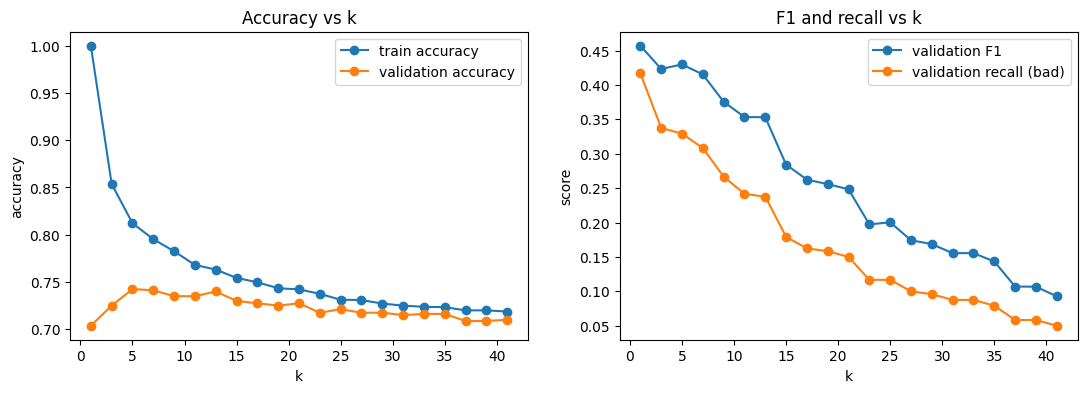

k with the best validation F1: 1


In [14]:
ks = list(range(1, 42, 2))
rows = []
for kk in ks:
    res = cross_validate(make_pipe(n_neighbors=kk), X_train, y_train, cv=cv,
                         scoring=scoring, return_train_score=True)
    rows.append({
        'k': kk,
        'train_acc': res['train_acc'].mean(),
        'val_acc': res['test_acc'].mean(),
        'val_f1': res['test_f1'].mean(),
        'val_recall': res['test_recall'].mean(),
    })

k_table = pd.DataFrame(rows)
print(k_table.round(3).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(k_table['k'], k_table['train_acc'], marker='o', label='train accuracy')
ax[0].plot(k_table['k'], k_table['val_acc'], marker='o', label='validation accuracy')
ax[0].set_xlabel("k"); ax[0].set_ylabel("accuracy"); ax[0].legend()
ax[0].set_title("Accuracy vs k")

ax[1].plot(k_table['k'], k_table['val_f1'], marker='o', label='validation F1')
ax[1].plot(k_table['k'], k_table['val_recall'], marker='o', label='validation recall (bad)')
ax[1].set_xlabel("k"); ax[1].set_ylabel("score"); ax[1].legend()
ax[1].set_title("F1 and recall vs k")
plt.show()

best_k_f1 = int(k_table.loc[k_table['val_f1'].idxmax(), 'k'])
print("k with the best validation F1:", best_k_f1)

## 7. Grid Search: k, Weights and Distance Metric

| Setting | Values |
|---|---|
| `n_neighbors` | 3, 5, 7, 9, 11, 15, 21, 31 |
| `weights` | uniform, distance |
| `metric` | euclidean, manhattan |

Scoring: **F1** of the bad class, with 5-fold CV on the training set.

In [15]:
param_grid = {
    'knn__n_neighbors': [3, 5, 7, 9, 11, 15, 21, 31],
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['euclidean', 'manhattan'],
}

grid = GridSearchCV(make_pipe(), param_grid, scoring='f1', cv=cv, n_jobs=-1, refit=True)
grid.fit(X_train, y_train)

print("Best settings:", grid.best_params_)
print("Best cross-validated F1:", round(grid.best_score_, 3))

results = pd.DataFrame(grid.cv_results_)
cols = ['param_knn__n_neighbors', 'param_knn__weights', 'param_knn__metric',
        'mean_test_score', 'rank_test_score']
print(results.sort_values('rank_test_score')[cols].head(6).round(3).to_string(index=False))

Best settings: {'knn__metric': 'manhattan', 'knn__n_neighbors': 5, 'knn__weights': 'distance'}
Best cross-validated F1: 0.457
 param_knn__n_neighbors param_knn__weights param_knn__metric  mean_test_score  rank_test_score
                      5           distance         manhattan            0.457                1
                      5            uniform         manhattan            0.455                2
                      7           distance         manhattan            0.440                3
                      9           distance         manhattan            0.439                4
                      5           distance         euclidean            0.434                5
                      5            uniform         euclidean            0.430                6


## 8. Curse of Dimensionality

**Experiment 1:** random points. We measure the ratio **nearest distance / farthest distance** as the number of dimensions grows. A ratio near 1 means "nearest" and "farthest" are almost the same, so neighbours stop being meaningful.

**Experiment 2:** we add pure **noise columns** (random numbers with no information) to our real data and watch KNN's validation score fall.

> For experiment 2 the preprocessing is fitted on the whole training set once, so this is a **demonstration**, not a model for final reporting.

In [16]:
rng = np.random.RandomState(42)

# Experiment 1: nearest vs farthest distance in random data
for d in [2, 10, 50, 200, 1000]:
    pts = rng.rand(500, d)
    dist = np.sqrt(((pts[1:] - pts[0]) ** 2).sum(axis=1))
    print(f"dimensions = {d:5d} | nearest / farthest = {dist.min() / dist.max():.3f}")

dimensions =     2 | nearest / farthest = 0.023
dimensions =    10 | nearest / farthest = 0.329
dimensions =    50 | nearest / farthest = 0.626
dimensions =   200 | nearest / farthest = 0.785
dimensions =  1000 | nearest / farthest = 0.909


   noise columns added  val_acc  val_f1
0                    0    0.732   0.291
1                   10    0.721   0.198
2                   30    0.709   0.120
3                   60    0.699   0.103
4                  100    0.709   0.206
5                  200    0.679   0.051


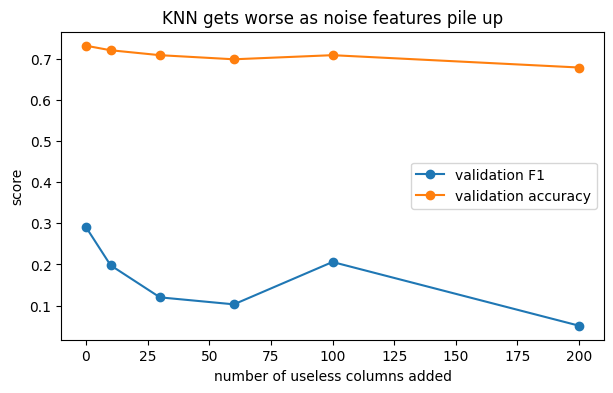

In [17]:
# Experiment 2: add useless noise columns to our real (processed) data
base = clone(preprocess).fit_transform(X_train).values
rows = []
for n_noise in [0, 10, 30, 60, 100, 200]:
    Xn = np.hstack([base, rng.randn(len(base), n_noise)])
    res = cross_validate(KNeighborsClassifier(n_neighbors=15), Xn, y_train, cv=cv,
                         scoring={'acc': 'accuracy', 'f1': 'f1'})
    rows.append({'noise columns added': n_noise,
                 'val_acc': res['test_acc'].mean(),
                 'val_f1': res['test_f1'].mean()})

noise_table = pd.DataFrame(rows).round(3)
print(noise_table)

plt.figure(figsize=(7, 4))
plt.plot(noise_table['noise columns added'], noise_table['val_f1'], marker='o', label='validation F1')
plt.plot(noise_table['noise columns added'], noise_table['val_acc'], marker='o', label='validation accuracy')
plt.xlabel("number of useless columns added")
plt.ylabel("score")
plt.title("KNN gets worse as noise features pile up")
plt.legend()
plt.show()

## 9. Choosing the Threshold Without Touching the Test Set

KNN's probability is just the share of bad neighbours, so with k = 11 it takes values like 0/11, 1/11, ... 11/11.

Steps:

1. get **out-of-fold probabilities** for the training rows with `cross_val_predict`: each row is predicted by a model that has **not** seen it
2. for each threshold compute the cost (5 x FN + FP) on those predictions
3. pick the threshold with the lowest cost
4. apply it to the test set **once**

> This follows Day 10's rule: the test set stays a fair final exam.

In [18]:
best_knn = grid.best_estimator_

# Out-of-fold probability of "bad" for every training row
oof = cross_val_predict(clone(best_knn), X_train, y_train, cv=cv, method='predict_proba')[:, 1]

rows = []
for t in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]:
    p = (oof >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, p).ravel()
    rows.append({'threshold': t, 'recall': round(recall_score(y_train, p), 3),
                 'precision': round(precision_score(y_train, p, zero_division=0), 3),
                 'FN': fn, 'FP': fp, 'cost': 5 * fn + fp})

thr_table = pd.DataFrame(rows)
print(thr_table.to_string(index=False))

best_thr = thr_table.loc[thr_table['cost'].idxmin(), 'threshold']
print("\nThreshold with the lowest cost on out-of-fold predictions:", best_thr)

 threshold  recall  precision  FN  FP  cost
       0.1   0.850      0.384  36 327   507
       0.2   0.688      0.457  75 196   571
       0.3   0.596      0.524  97 130   615
       0.4   0.479      0.596 125  78   703
       0.5   0.358      0.632 154  50   820
       0.6   0.258      0.660 178  32   922

Threshold with the lowest cost on out-of-fold predictions: 0.1


## 10. Final Evaluation on the Test Set (once)

We compare four models on the untouched test set:

| Model | Idea |
|---|---|
| baseline | always good |
| KNN default | k = 5, uniform weights, Euclidean |
| KNN tuned | best settings from the grid search |
| KNN tuned + threshold | same, with the cost-based threshold from Section 9 |

> After this table we do **not** go back and re-tune.

In [19]:
baseline = Pipeline([('prep', clone(preprocess)),
                     ('dummy', DummyClassifier(strategy='most_frequent'))]).fit(X_train, y_train)
knn_default = make_pipe(n_neighbors=5).fit(X_train, y_train)

proba_test = best_knn.predict_proba(X_test)[:, 1]

final = pd.DataFrame([
    evaluate('baseline (always good)', y_test, baseline.predict(X_test)),
    evaluate('KNN default (k=5)', y_test, knn_default.predict(X_test)),
    evaluate('KNN tuned', y_test, best_knn.predict(X_test)),
    evaluate(f'KNN tuned + threshold {best_thr}', y_test, (proba_test >= best_thr).astype(int)),
])
print(final.to_string(index=False))

                    model  accuracy  precision  recall    f1  FN  FP  cost
   baseline (always good)     0.700      0.000   0.000 0.000  60   0   300
        KNN default (k=5)     0.725      0.568   0.350 0.433  39  16   211
                KNN tuned     0.730      0.575   0.383 0.460  37  17   202
KNN tuned + threshold 0.1     0.515      0.374   0.917 0.531   5  92   117


## 11. KNN: Summary

| Strengths | Weaknesses |
|---|---|
| very simple and intuitive | needs scaling |
| no training step | slow prediction (distance to every row) |
| works with any distance | needs the whole training set in memory |
| few hyperparameters | hurt by irrelevant features (curse of dimensionality) |
| naturally non-linear | one-hot features can dominate the distance |
|  | no built-in class weighting for imbalance |

**Hyperparameters:** `n_neighbors`, `weights`, `metric` (and `p` for Minkowski).